In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from tqdm import tqdm
from utils import SimpleDatasetMaker, ratemap_collage
import scipy
import matplotlib.patches as patches

In [ ]:
# Optimization model
class OptimizationModel:
    def __init__(self, d = 256):
        k = 1/np.sqrt(d)
        self.A = torch.tensor(k*np.random.uniform(-1, 1, (d, d)),  requires_grad=True, dtype=torch.float32)
        self.B = torch.tensor(k*np.random.uniform(-1, 1, (d, d)),  requires_grad=True, dtype=torch.float32)
        self.d = d
        self.optimizer = torch.optim.Adam([self.A, self.B], lr=0.001)

    def objective_function(self, p0, pt, dr):
        # Compute e^(A + B)
        C = torch.matrix_exp(dr[...,0, None, None]*self.A[None] + dr[...,1,None,None]*self.B[None])
        p_pred = torch.bmm(C, p0[...,None]).squeeze()

        # require commutation
        commutation_loss = torch.mean((self.A@self.B - self.B@self.A)**2)
        return torch.mean((pt - p_pred)**2) + commutation_loss

    def optimize(self, n, ratemaps, bs = 32):
        self.loss_history = []

        s = ratemaps.shape[0] # size; arena is square

        for _ in tqdm(range(n)):
            self.optimizer.zero_grad()  # Clear previous gradients
            # starting pixels
            i0 = torch.randint(0, s, size = (bs, 2))
            # pixel step
            di = torch.randint(-2, 3, size = (bs, 2))
            # check if in bounds; reverse velocity if steps lands outside
            i_trial = i0 + di
            upper_mask = i_trial >= s
            lower_mask = i_trial < 0
            mask = upper_mask + lower_mask
            di = -di*(mask) + di*(~mask)
            it = i0 + di # valid step

            # it = torch.randint(0, ratemaps.shape[0]-1, size = (bs, 2))
            # di = it - i0
            dr = (2/ratemaps.shape[0])*di.float() # one pixel is [-1, 1]/32 = 2/32 = 1/16 in baseline env
            # 32 px = 2 ; 1 px = # 2/32 = 1/16
            loss = self.objective_function(ratemaps[i0[:,0], i0[:,1]], ratemaps[it[:,0], it[:,1]], dr)  # Compute the loss
            loss.backward()  # Backpropagation
            self.optimizer.step()  # Update parameters
            self.loss_history.append(loss.item())
        return self.loss_history


torch.Size([32, 32, 102])

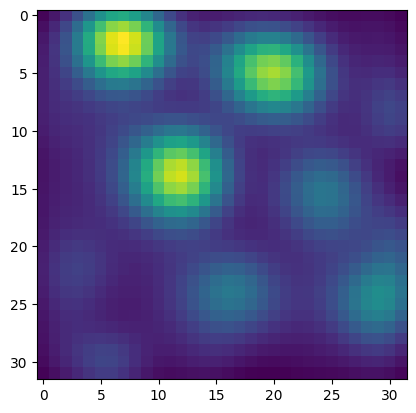

In [3]:
# load data
original_ratemaps = np.load("gc_ratmaps.npy").astype("float32")
original_ratemaps = np.transpose(original_ratemaps, (1,2,0))
plt.imshow(original_ratemaps[...,0])

ratemaps = torch.tensor(original_ratemaps)
ratemaps.shape

In [ ]:
model = OptimizationModel(d = ratemaps.shape[-1])   

In [5]:
loss_history = model.optimize(20000, ratemaps)

100%|██████████| 20000/20000 [11:53<00:00, 28.03it/s]


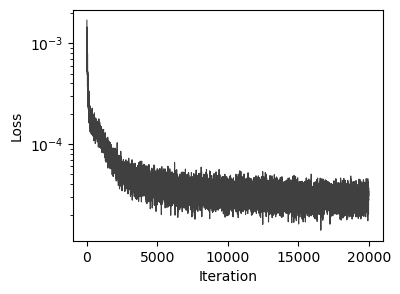

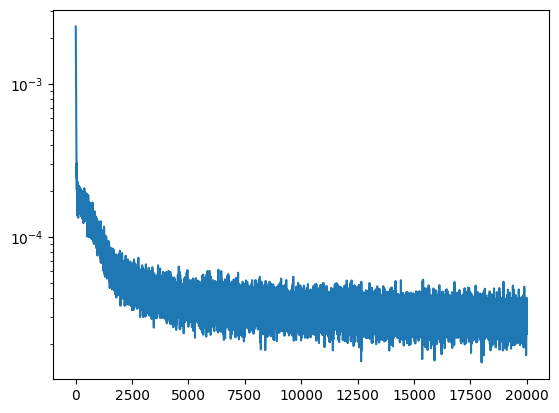

In [14]:
plt.figure(figsize = (4,3))
plt.semilogy(model.loss_history, "k", linewidth = 0.8, alpha = 0.75)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.savefig("./figures/experimental_loss_curve.svg", dpi = 300, bbox_inches = "tight")

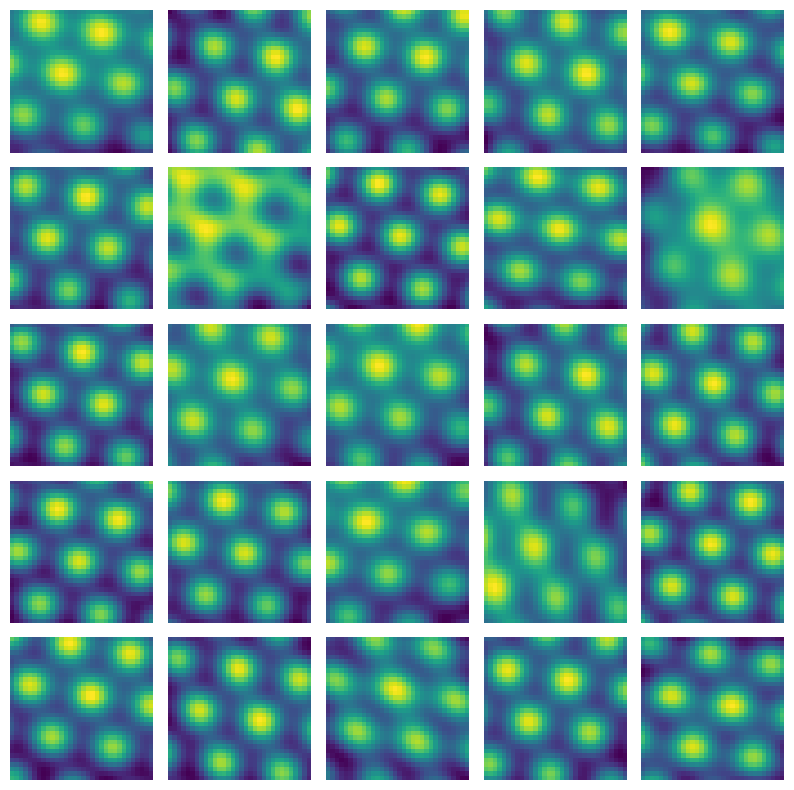

In [8]:
rg = np.arange(32)
xxg, yyg = np.meshgrid(rg, rg)
rrg = np.stack((xxg.ravel(), yyg.ravel()), axis = -1)
v = rrg - 16 # shift to center, dt = 1
v = v/16 # 32 pixels = [-1, 1] ; 1 pixel = 2/32 = 1/16
# only generation 
p_prime = torch.full((ratemaps.shape[-1], len(v)), torch.nan, dtype = torch.float32)
p0 = ratemaps[ratemaps.shape[0]//2, ratemaps.shape[1]//2]

for i in range(len(v)):
    C = v[i,0]*model.A + v[i,1]*model.B
    Q = torch.matrix_exp(C)
    p_prime[:,i] = Q@p0
    p_prev = p_prime[:,i]
p_prime = p_prime.detach().numpy()
bins = original_ratemaps.shape[0]

rmap = p_prime.reshape((-1, bins, bins)).transpose((0, 2, 1))
ratemap_collage(rmap, figsize = (10,10))
plt.savefig('./figures/generated_ratemaps_same_size.svg', dpi=300, bbox_inches='tight')

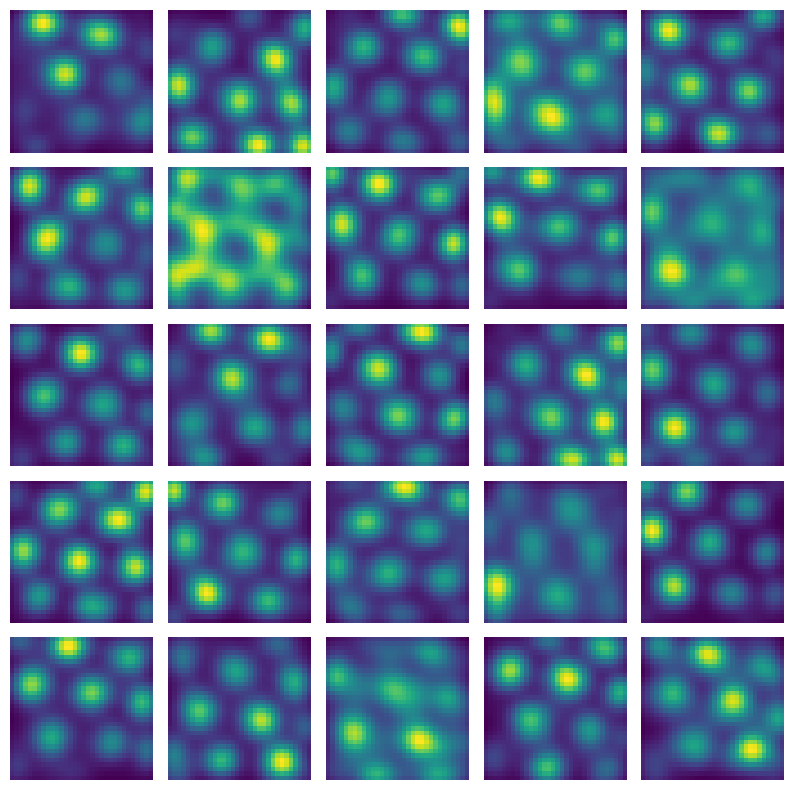

In [19]:
ratemap_collage(original_ratemaps.transpose(2, 0, 1)[:100], 5, 5, figsize = (10,10));
plt.savefig('./figures/experimental_ratemaps.svg', dpi=300, bbox_inches='tight')

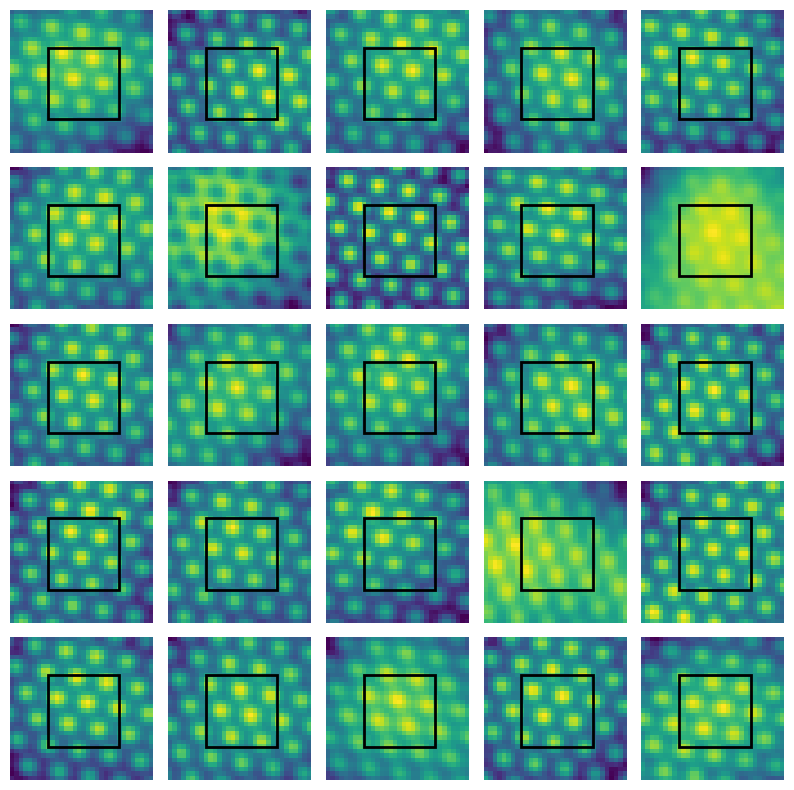

In [31]:
rg = np.arange(32)
xxg, yyg = np.meshgrid(rg, rg)
rrg = np.stack((xxg.ravel(), yyg.ravel()), axis = -1)
v2 = rrg - 16 # shift to center, dt = 1
v2 = 2*v2/16 # double all movement lengths to double chamber size
# only generation 
p_prime = torch.full((ratemaps.shape[-1], len(v)), torch.nan, dtype = torch.float32)
p0 = ratemaps[ratemaps.shape[0]//2, ratemaps.shape[1]//2]

for i in range(len(v)):
    C = v2[i,0]*model.A + v2[i,1]*model.B
    Q = torch.matrix_exp(C)
    p_prime[:,i] = Q@p0
    p_prev = p_prime[:,i]
p_prime = p_prime.detach().numpy()
bins = original_ratemaps.shape[0]

rmap = p_prime.reshape((-1, bins, bins)).transpose((0, 2, 1))
figs, axs = ratemap_collage(rmap, figsize = (10,10))

for ax in axs.flatten():
    square = patches.Rectangle((8, 8), 16, 16, linewidth=2, edgecolor='k', facecolor='none')
    ax.add_patch(square)

plt.savefig('./figures/generated_ratemaps_double_size.svg', dpi=300, bbox_inches='tight')

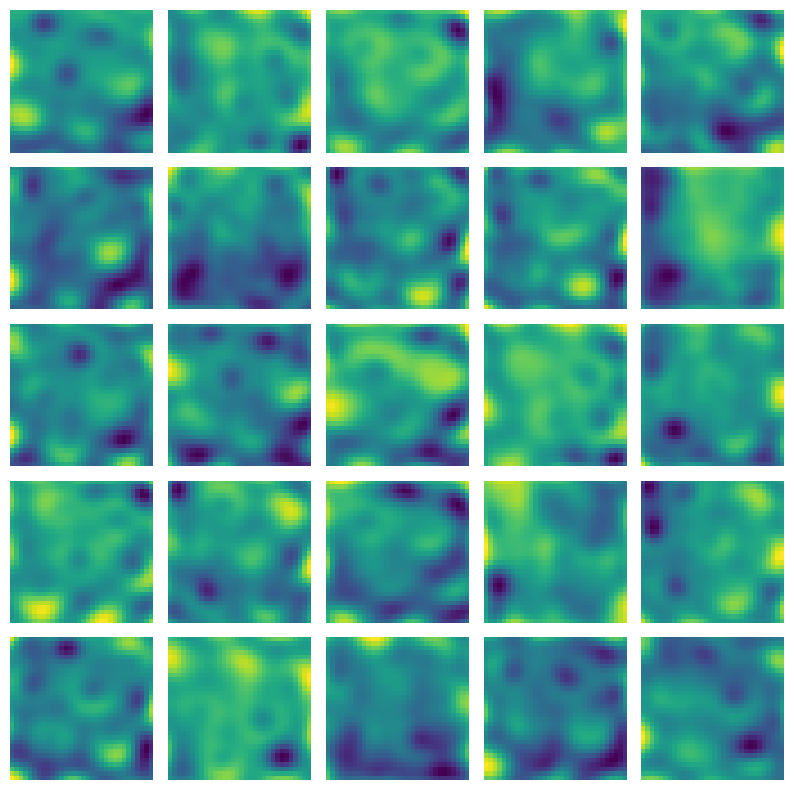

In [10]:
ratemap_diff = rmap - original_ratemaps.transpose(2, 0, 1)
ratemap_collage(ratemap_diff, 5, 5, figsize = (10,10)); 

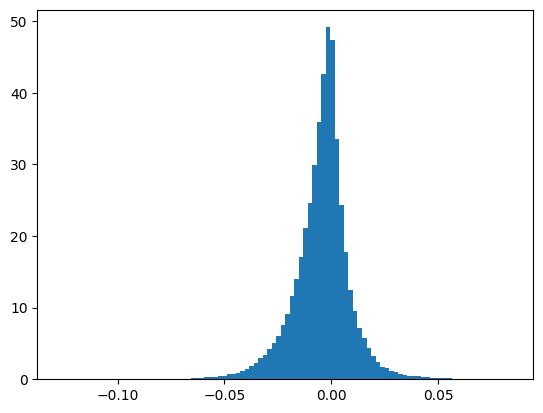

In [11]:
plt.hist(ratemap_diff.ravel(), density =True, bins = 100);

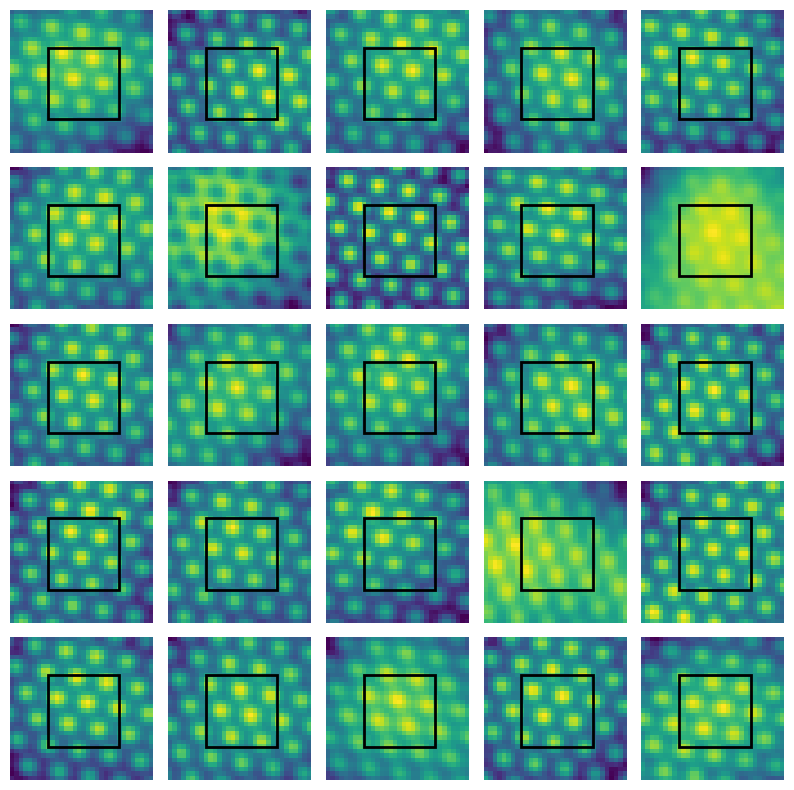

In [ ]:
commutator = (model.A@model.B - model.B@model.A).detach().numpy()
plt.imshow(commutator)
plt.colorbar()

In [ ]:
A_sym = (model.A + model.A.T).detach().numpy()
B_sym = (model.B + model.B.T).detach().numpy()
plt.imshow(A_sym)
plt.colorbar()
plt.title("A+A^T")


In [ ]:
plt.imshow(B_sym)
plt.colorbar()
plt.title("B + B^T")